<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter4/pendulum_bug_slow_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Numerical Exploration of the bug on a pendulum equation of motion in the Slow Approximation via 4th order Runge-Kutta

<>:243: SyntaxWarning: invalid escape sequence '\c'
<>:243: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_3143/1374863447.py:243: SyntaxWarning: invalid escape sequence '\c'
  ax.set_title(f'{case["name"]}\n($\\theta_0={np.rad2deg(th0):.0f}^\circ$, $\\dot{{\\theta}}_0={om0:.2f}$)')


Simulating 1. Small Angle (Ping Pong)...
Simulating 2. Small Angle (Harmonic)...
Simulating 3. Large Angle (Ping Pong)...
Simulating 4. Large Angle (Harmonic)...
Simulating 5. Slow Rot -> Osc (Ping Pong)...
Simulating 6. Slow Rot -> Osc (Harmonic)...
Simulating 7. Fast Rot Marginal (Ping Pong)...
Simulating 8. Fast Rot Marginal (Harmonic)...
Simulating 9. Very Fast Cont Rot (Ping Pong)...
Simulating 10. Very Fast Cont Rot (Harmonic)...
Calculating boundaries for the mathematical phase space map...


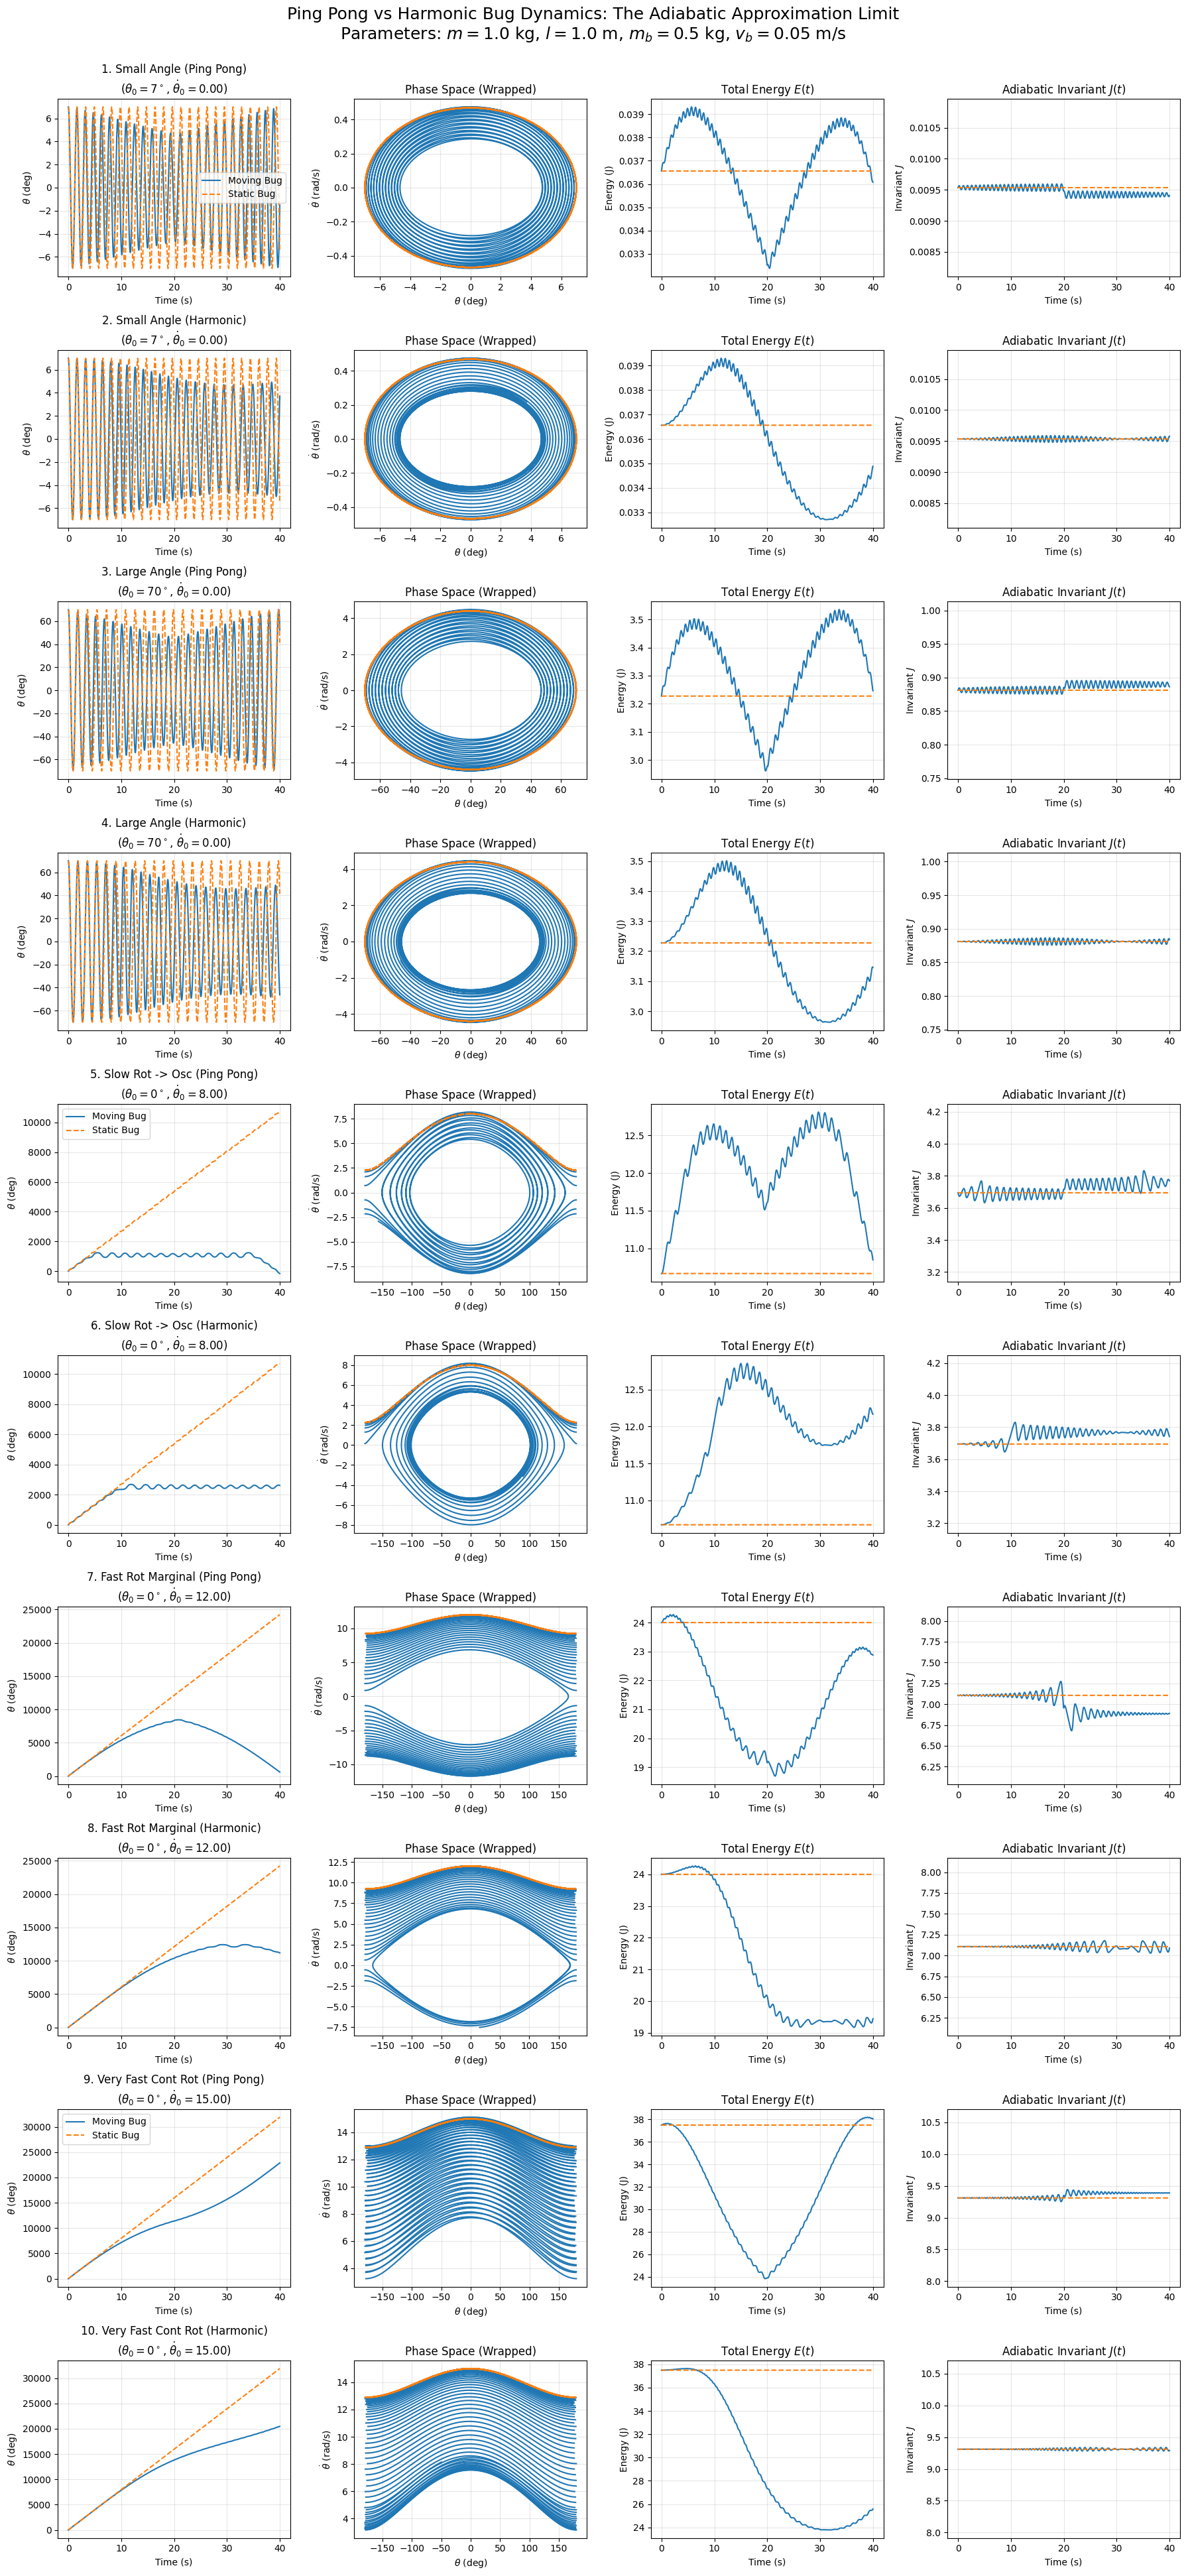

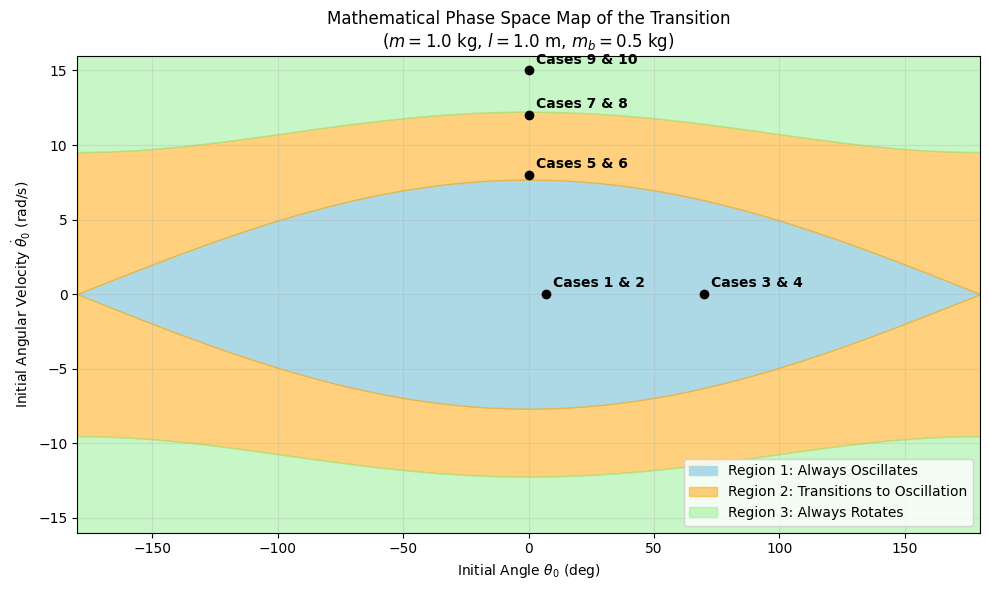

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import brentq
import warnings
from collections import defaultdict

# Suppress scipy.integrate warnings near the separatrix turning points
warnings.filterwarnings("ignore")

def get_r_v(t, v_b, p):
    """
    Calculates the bug's position r(t) and velocity r_dot(t).
    Supports both 'pingpong' (constant velocity) and 'harmonic' (smooth) modes.
    """
    l = p['l']
    if v_b == 0:
        return 0.0, 0.0 # Static bug at the pivot

    mode = p.get('mode', 'pingpong')

    if mode == 'pingpong':
        s = v_b * t
        mod_s = s % (2 * l)
        if mod_s < l:
            return mod_s, v_b        # Moving down
        else:
            return 2 * l - mod_s, -v_b # Moving up

    elif mode == 'harmonic':
        # Harmonic motion matching the same average speed/extents
        omega_b = 2 * v_b / l
        r = (l / 2) * (1 - np.cos(omega_b * t))
        r_dot = (l / 2) * omega_b * np.sin(omega_b * t)
        return r, r_dot

def dy_dt(t, y, v_b, p):
    """ Exact Newtonian Equation of Motion for the bug-pendulum system. """
    theta, omega = y
    r, r_dot = get_r_v(t, v_b, p)

    # Instantaneous Moment of Inertia and Effective Mass Lever
    I = (1/3) * p['m'] * p['l']**2 + p['m_b'] * r**2
    M_eff = 0.5 * p['m'] * p['l'] + p['m_b'] * r

    # Exact EOM including the Coriolis term
    alpha = (- 2 * p['m_b'] * r * r_dot * omega - M_eff * p['g'] * np.sin(theta)) / I

    return np.array([omega, alpha])

def calc_E(y, t, v_b, p):
    """ Calculates the total instantaneous mechanical energy E(t). """
    theta, omega = y
    r, _ = get_r_v(t, v_b, p)

    I = (1/3) * p['m'] * p['l']**2 + p['m_b'] * r**2
    M_eff = 0.5 * p['m'] * p['l'] + p['m_b'] * r

    # Potential energy set to 0 at the bottom
    V = M_eff * p['g'] * (1 - np.cos(theta))
    T = 0.5 * I * omega**2

    return T + V

def calc_J(E, t, v_b, p):
    """ Calculates the generalized adiabatic invariant (Action J). """
    r, _ = get_r_v(t, v_b, p)

    I = (1/3) * p['m'] * p['l']**2 + p['m_b'] * r**2
    M_eff = 0.5 * p['m'] * p['l'] + p['m_b'] * r

    max_V = 2 * M_eff * p['g']

    if E < max_V:
        # --- OSCILLATING REGIME ---
        val = 1.0 - E / (M_eff * p['g'])
        val = max(-1.0, min(1.0, val))
        theta_max = np.arccos(val)

        def integrand(theta):
            V = M_eff * p['g'] * (1 - np.cos(theta))
            arg = max(0.0, E - V)
            return np.sqrt(2 * I * arg)

        res, _ = quad(integrand, 0, theta_max, limit=100)
        return (4 * res) / (2 * np.pi)

    else:
        # --- ROTATING REGIME ---
        def integrand(theta):
            V = M_eff * p['g'] * (1 - np.cos(theta))
            arg = max(0.0, E - V)
            return np.sqrt(2 * I * arg)

        res, _ = quad(integrand, 0, 2 * np.pi, limit=100)
        return (2 * res) / (2 * np.pi)

def solve_rk4(y0, v_b, p, t_span, dt=0.01):
    """ 4th Order Runge-Kutta integrator. """
    t_vals = np.arange(t_span[0], t_span[1], dt)
    y_vals = np.zeros((len(t_vals), 2))
    y_vals[0] = y0

    for i in range(1, len(t_vals)):
        t = t_vals[i-1]
        y = y_vals[i-1]

        k1 = dy_dt(t, y, v_b, p)
        k2 = dy_dt(t + 0.5*dt, y + 0.5*dt*k1, v_b, p)
        k3 = dy_dt(t + 0.5*dt, y + 0.5*dt*k2, v_b, p)
        k4 = dy_dt(t + dt, y + dt*k3, v_b, p)

        y_vals[i] = y + (dt/6.0) * (k1 + 2*k2 + 2*k3 + k4)

    return t_vals, y_vals

def plot_phase_space(ax, theta, omega, color, label=None, linestyle='-'):
    """ Wraps theta to [-pi, pi] and plots phase space without connecting jump lines in degrees. """
    theta_wrap = (theta + np.pi) % (2 * np.pi) - np.pi
    jumps = np.where(np.abs(np.diff(theta_wrap)) > np.pi)[0] + 1

    theta_split = np.split(theta_wrap, jumps)
    omega_split = np.split(omega, jumps)

    for i in range(len(theta_split)):
        lbl = label if i == 0 else None
        # Convert the wrapped angles to degrees for plotting
        ax.plot(np.rad2deg(theta_split[i]), omega_split[i], color=color, linestyle=linestyle, label=lbl)

def plot_transition_map(p, cases):
    """ Mathematically plots the transition boundaries in the initial phase space. """
    theta_vals_rad = np.linspace(-np.pi, np.pi, 300)
    theta_vals_deg = np.rad2deg(theta_vals_rad)

    I_0 = (1/3) * p['m'] * p['l']**2
    M_eff_0 = 0.5 * p['m'] * p['l']
    E_sep_0 = 2 * M_eff_0 * p['g']

    I_l = (1/3) * p['m'] * p['l']**2 + p['m_b'] * p['l']**2
    M_eff_l = 0.5 * p['m'] * p['l'] + p['m_b'] * p['l']

    J_sep_l = (8 / np.pi) * np.sqrt(I_l * M_eff_l * p['g'])

    def obj(E):
        return calc_J(E, 0, 0, p) - J_sep_l

    E_crit = brentq(obj, E_sep_0 + 1e-4, E_sep_0 + 500)

    omega_sep = np.sqrt(2 * (E_sep_0 - M_eff_0 * p['g'] * (1 - np.cos(theta_vals_rad))) / I_0)
    omega_crit = np.sqrt(2 * (E_crit - M_eff_0 * p['g'] * (1 - np.cos(theta_vals_rad))) / I_0)

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.fill_between(theta_vals_deg, -omega_sep, omega_sep, color='lightblue', label='Region 1: Always Oscillates')
    ax.fill_between(theta_vals_deg, omega_sep, omega_crit, color='orange', alpha=0.5, label='Region 2: Transitions to Oscillation')
    ax.fill_between(theta_vals_deg, -omega_crit, -omega_sep, color='orange', alpha=0.5)
    ax.fill_between(theta_vals_deg, omega_crit, 20, color='lightgreen', alpha=0.5, label='Region 3: Always Rotates')
    ax.fill_between(theta_vals_deg, -20, -omega_crit, color='lightgreen', alpha=0.5)

    # Group coordinates to avoid overlapping annotations for the identical paired cases
    coords_to_cases = defaultdict(list)
    for i, case in enumerate(cases):
        th0_rad, om0 = case["y0"]
        th0_deg = np.rad2deg(th0_rad)
        coords_to_cases[(th0_deg, om0)].append(i + 1)

    for (th0_deg, om0), case_nums in coords_to_cases.items():
        ax.plot(th0_deg, om0, 'ko', markersize=6)
        case_str = " & ".join(f"{n}" for n in case_nums)
        ax.annotate(f"Cases {case_str}", (th0_deg, om0), textcoords="offset points", xytext=(5,5), ha='left', fontsize=10, fontweight='bold')

    ax.set_ylim(-16, 16)
    ax.set_xlim(-180, 180)
    ax.set_xlabel(r'Initial Angle $\theta_0$ (deg)')
    ax.set_ylabel(r'Initial Angular Velocity $\dot{\theta}_0$ (rad/s)')
    ax.set_title(f'Mathematical Phase Space Map of the Transition\n($m={p["m"]}$ kg, $l={p["l"]}$ m, $m_b={p["m_b"]}$ kg)')
    ax.legend(loc='lower right')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()

def main():
    # Physical Parameters
    p_base = {
        'm': 1.0,      # mass of rod (kg)
        'l': 1.0,      # length of rod (m)
        'm_b': 0.5,    # mass of bug (kg)
        'g': 9.81      # gravity (m/s^2)
    }

    # 10 Specific Cases: Pairing ping-pong and harmonic modes for each initial condition
    cases = [
        {"name": "1. Small Angle (Ping Pong)", "y0": [7 * np.pi / 180, 0.0], "mode": "pingpong"},
        {"name": "2. Small Angle (Harmonic)", "y0": [7 * np.pi / 180, 0.0], "mode": "harmonic"},

        {"name": "3. Large Angle (Ping Pong)", "y0": [70 * np.pi / 180, 0.0], "mode": "pingpong"},
        {"name": "4. Large Angle (Harmonic)", "y0": [70 * np.pi / 180, 0.0], "mode": "harmonic"},

        {"name": "5. Slow Rot -> Osc (Ping Pong)", "y0": [0.0, 8.0], "mode": "pingpong"},
        {"name": "6. Slow Rot -> Osc (Harmonic)", "y0": [0.0, 8.0], "mode": "harmonic"},

        {"name": "7. Fast Rot Marginal (Ping Pong)", "y0": [0.0, 12.0], "mode": "pingpong"},
        {"name": "8. Fast Rot Marginal (Harmonic)", "y0": [0.0, 12.0], "mode": "harmonic"},

        {"name": "9. Very Fast Cont Rot (Ping Pong)", "y0": [0.0, 15.0], "mode": "pingpong"},
        {"name": "10. Very Fast Cont Rot (Harmonic)", "y0": [0.0, 15.0], "mode": "harmonic"}
    ]

    v_b_slow = 0.05
    t_span = [0, 40]

    # Figure 1: Time Series and Phase Space
    fig, axes = plt.subplots(len(cases), 4, figsize=(18, 4 * len(cases)))
    plt.subplots_adjust(hspace=0.4, wspace=0.3)

    for i, case in enumerate(cases):
        print(f"Simulating {case['name']}...")

        # Inject the specific bug movement mode into the parameters
        p = p_base.copy()
        p['mode'] = case['mode']

        # --- Simulate Moving Bug ---
        t_s, y_s = solve_rk4(case["y0"], v_b_slow, p, t_span)
        E_s = [calc_E(y, t, v_b_slow, p) for y, t in zip(y_s, t_s)]
        J_s = [calc_J(E, t, v_b_slow, p) for E, t in zip(E_s, t_s)]

        # --- Simulate Static Bug (v_b = 0) ---
        t_0, y_0 = solve_rk4(case["y0"], 0.0, p, t_span)
        E_0 = [calc_E(y, t, 0.0, p) for y, t in zip(y_0, t_0)]
        J_0 = [calc_J(E, t, 0.0, p) for E, t in zip(E_0, t_0)]

        theta_s, omega_s = y_s[:, 0], y_s[:, 1]
        theta_0, omega_0 = y_0[:, 0], y_0[:, 1]

        th0, om0 = case["y0"]

        # 1. Plot Theta(t)
        ax = axes[i, 0]
        ax.plot(t_s, np.rad2deg(theta_s), label=f'Moving Bug', color='C0')
        ax.plot(t_0, np.rad2deg(theta_0), label=f'Static Bug', linestyle='--', color='C1')
        ax.set_ylabel(r'$\theta$ (deg)')
        ax.set_xlabel('Time (s)')
        ax.set_title(f'{case["name"]}\n($\\theta_0={np.rad2deg(th0):.0f}^\circ$, $\\dot{{\\theta}}_0={om0:.2f}$)')
        ax.grid(True, alpha=0.3)
        if i in [0, 4, 8]: ax.legend()

        # 2. Plot Phase Space
        ax = axes[i, 1]
        plot_phase_space(ax, theta_s, omega_s, color='C0', label=f'Moving Bug')
        plot_phase_space(ax, theta_0, omega_0, color='C1', label='Static', linestyle='--')
        ax.set_xlabel(r'$\theta$ (deg)')
        ax.set_ylabel(r'$\dot{\theta}$ (rad/s)')
        ax.set_title('Phase Space (Wrapped)')
        ax.grid(True, alpha=0.3)

        # 3. Plot Energy
        ax = axes[i, 2]
        ax.plot(t_s, E_s, color='C0')
        ax.plot(t_0, E_0, linestyle='--', color='C1')
        ax.set_xlabel('Time (s)')
        ax.set_ylabel('Energy (J)')
        ax.set_title('Total Energy $E(t)$')
        ax.grid(True, alpha=0.3)

        # 4. Plot Adiabatic Invariant
        ax = axes[i, 3]
        ax.plot(t_s, J_s, color='C0')
        ax.plot(t_0, J_0, linestyle='--', color='C1')
        ax.set_xlabel('Time (s)')
        ax.set_ylabel('Invariant $J$')
        ax.set_title('Adiabatic Invariant $J(t)$')
        ax.grid(True, alpha=0.3)

        # Set tight Y-axis for J to prove it remains strictly flat for v_b=0
        J_mean = np.mean(J_0)
        ax.set_ylim(J_mean * 0.85, J_mean * 1.15)

    plt.suptitle(f"Ping Pong vs Harmonic Bug Dynamics: The Adiabatic Approximation Limit\n"
                 f"Parameters: $m={p_base['m']}$ kg, $l={p_base['l']}$ m, $m_b={p_base['m_b']}$ kg, $v_b={v_b_slow}$ m/s",
                 fontsize=18)
    plt.tight_layout(rect=[0, 0.01, 1, 0.98])

    # Figure 2: The Transition Map overlayed with the cases
    print("Calculating boundaries for the mathematical phase space map...")
    # Map uses base parameters (ping-pong bounds are same as harmonic bounds)
    plot_transition_map(p_base, cases)

    plt.show()

if __name__ == "__main__":
    main()